# Olist Data Warehouse — EDA trên MySQL DW

Notebook này truy vấn trực tiếp database `olist_dw` trong Docker, **không đọc các CSV RAW**. Cấu trúc gồm 5 phần: Data Understanding, Data Quality Assessment, EDA, Business Analysis, Statistical Analysis & Hypothesis Testing.

**Quy tắc grain quan trọng**
- Không JOIN trực tiếp `fact_order_items` với `fact_payments` hoặc `fact_reviews` rồi cộng tổng: quan hệ một-nhiều có thể nhân bản giá trị.
- Doanh thu sản phẩm trong notebook được định nghĩa là `SUM(fact_order_items.price)`; bộ lọc trạng thái được nêu rõ ở từng phân tích.
- Điểm đánh giá theo đơn được tính bằng `AVG(review_score)` theo `order_key`. Đây là quy ước phân tích của notebook.
- Công thức ETL của `item_total`, `delivery_days`, `delivery_delay_days`, `total_spent`, `average_order_value` cần được đối chiếu với code ETL trước khi kết luận.
- Tháng cuối kỳ có thể chưa đầy đủ; không diễn giải như tháng hoàn chỉnh nếu chưa xác nhận độ bao phủ.

## 0. Cài đặt và kết nối

Mặc định theo môi trường đã trao đổi: `127.0.0.1:3307`, database `olist_dw`, user `olist`. Nếu Jupyter chạy trong container khác, `127.0.0.1` có thể không trỏ đến MySQL container.

In [4]:
# Nếu thiếu thư viện, bỏ comment và chạy:
%pip install pandas numpy matplotlib seaborn scipy sqlalchemy pymysql statsmodels

import os
import warnings
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

DB_HOST = os.getenv("OLIST_DB_HOST", "127.0.0.1")
DB_PORT = int(os.getenv("OLIST_DB_PORT", "3307"))
DB_NAME = os.getenv("OLIST_DB_NAME", "olist_dw")
DB_USER = os.getenv("OLIST_DB_USER", "olist")
DB_PASSWORD = os.getenv("OLIST_DB_PASSWORD", "olist123")

url = (f"mysql+pymysql://{quote_plus(DB_USER)}:{quote_plus(DB_PASSWORD)}"
       f"@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4")
engine = create_engine(url, pool_pre_ping=True, pool_recycle=3600)

def qdf(query, params=None):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params or {})

display(qdf("SELECT DATABASE() AS database_name, VERSION() AS mysql_version, NOW() AS server_time"))

Note: you may need to restart the kernel to use updated packages.


,database_name,mysql_version,server_time
0,olist_dw,8.0.46,2026-10-09 18:58:01


# Phần 01 — Data Understanding

## 1.1. Quy mô, schema, grain và khóa

,TABLE_NAME,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE,COLUMN_KEY,EXTRA
0,dim_category,category_key,bigint,NO,PRI,
1,dim_category,product_category_name,varchar(150),NO,UNI,
2,dim_category,product_category_name_english,varchar(150),YES,,
3,dim_customer,customer_key,bigint,NO,PRI,
4,dim_customer,customer_unique_id,varchar(64),NO,UNI,
...,...,...,...,...,...,...
90,fact_reviews,review_comment_message,text,YES,,
91,fact_reviews,review_creation_date,datetime,YES,,
92,fact_reviews,review_answer_timestamp,datetime,YES,,
93,fact_reviews,is_positive,tinyint,YES,,


,table_name,row_count,column_count
0,dim_geolocation,19015,7
1,dim_category,71,3
2,dim_customer,96096,5
3,dim_seller,3095,5
4,dim_product,32951,11
5,dim_date,774,10
6,fact_orders,99441,15
7,fact_order_items,112650,11
8,fact_payments,103886,7
9,fact_reviews,98410,11


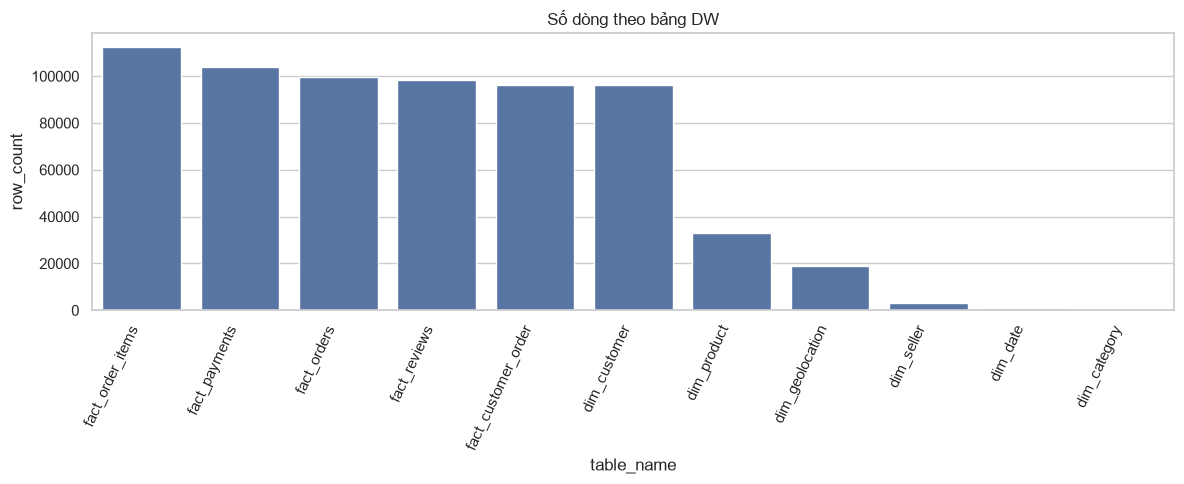

In [5]:
TABLES = [
    "dim_geolocation", "dim_category", "dim_customer", "dim_seller",
    "dim_product", "dim_date", "fact_orders", "fact_order_items",
    "fact_payments", "fact_reviews", "fact_customer_order"
]

schema_df = qdf("""
SELECT TABLE_NAME, COLUMN_NAME, COLUMN_TYPE, IS_NULLABLE, COLUMN_KEY, EXTRA
FROM information_schema.COLUMNS
WHERE TABLE_SCHEMA = :db
ORDER BY TABLE_NAME, ORDINAL_POSITION
""", {"db": DB_NAME})
display(schema_df)

row_counts = []
for t in TABLES:
    n = int(qdf(f"SELECT COUNT(*) AS n FROM `{t}`").loc[0, "n"])
    c = int((schema_df["TABLE_NAME"] == t).sum())
    row_counts.append({"table_name": t, "row_count": n, "column_count": c})
row_counts_df = pd.DataFrame(row_counts)
display(row_counts_df)

plt.figure(figsize=(12, 5))
sns.barplot(data=row_counts_df.sort_values("row_count", ascending=False), x="table_name", y="row_count")
plt.xticks(rotation=65, ha="right")
plt.title("Số dòng theo bảng DW")
plt.tight_layout()
plt.show()

In [6]:
grain_df = pd.DataFrame([
    ("dim_geolocation", "Một zip_code_prefix", "geolocation_key", "zip_code_prefix"),
    ("dim_category", "Một danh mục", "category_key", "product_category_name"),
    ("dim_customer", "Một khách hàng theo customer_unique_id", "customer_key", "customer_unique_id"),
    ("dim_seller", "Một seller", "seller_key", "seller_id"),
    ("dim_product", "Một sản phẩm", "product_key", "product_id"),
    ("dim_date", "Một ngày", "date_key", "date"),
    ("fact_orders", "Một đơn hàng", "order_key", "order_id"),
    ("fact_order_items", "Một dòng hàng trong đơn", "item_key", "order_id + order_item_id"),
    ("fact_payments", "Một lần thanh toán trong đơn", "payment_key", "order_id + payment_sequential"),
    ("fact_reviews", "Một bản ghi review", "review_key", "review_id"),
    ("fact_customer_order", "Một khách hàng với chỉ số hành vi tổng hợp", "customer_order_key", "customer_key")
], columns=["table_name", "grain", "primary_key", "business_key"])
display(grain_df)

constraints_df = qdf("""
SELECT tc.TABLE_NAME, tc.CONSTRAINT_NAME, tc.CONSTRAINT_TYPE,
       kcu.COLUMN_NAME, kcu.REFERENCED_TABLE_NAME, kcu.REFERENCED_COLUMN_NAME
FROM information_schema.TABLE_CONSTRAINTS tc
LEFT JOIN information_schema.KEY_COLUMN_USAGE kcu
  ON tc.CONSTRAINT_SCHEMA=kcu.CONSTRAINT_SCHEMA
 AND tc.TABLE_NAME=kcu.TABLE_NAME
 AND tc.CONSTRAINT_NAME=kcu.CONSTRAINT_NAME
WHERE tc.CONSTRAINT_SCHEMA=:db
ORDER BY tc.TABLE_NAME, tc.CONSTRAINT_TYPE, tc.CONSTRAINT_NAME, kcu.ORDINAL_POSITION
""", {"db": DB_NAME})
display(constraints_df)

,table_name,grain,primary_key,business_key
0,dim_geolocation,Một zip_code_prefix,geolocation_key,zip_code_prefix
1,dim_category,Một danh mục,category_key,product_category_name
2,dim_customer,Một khách hàng theo customer_unique_id,customer_key,customer_unique_id
3,dim_seller,Một seller,seller_key,seller_id
4,dim_product,Một sản phẩm,product_key,product_id
5,dim_date,Một ngày,date_key,date
6,fact_orders,Một đơn hàng,order_key,order_id
7,fact_order_items,Một dòng hàng trong đơn,item_key,order_id + order_item_id
8,fact_payments,Một lần thanh toán trong đơn,payment_key,order_id + payment_sequential
9,fact_reviews,Một bản ghi review,review_key,review_id


,TABLE_NAME,CONSTRAINT_NAME,CONSTRAINT_TYPE,COLUMN_NAME,REFERENCED_TABLE_NAME,REFERENCED_COLUMN_NAME
0,dim_category,PRIMARY,PRIMARY KEY,category_key,None,None
1,dim_category,uq_category_name,UNIQUE,product_category_name,None,None
2,dim_customer,fk_customer_geo,FOREIGN KEY,geolocation_key,dim_geolocation,geolocation_key
3,dim_customer,PRIMARY,PRIMARY KEY,customer_key,None,None
4,dim_customer,uq_customer_unique_id,UNIQUE,customer_unique_id,None,None
5,dim_date,PRIMARY,PRIMARY KEY,date_key,None,None
6,dim_date,uq_date,UNIQUE,date,None,None
7,dim_geolocation,PRIMARY,PRIMARY KEY,geolocation_key,None,None
8,dim_geolocation,uq_geo_zip,UNIQUE,zip_code_prefix,None,None
9,dim_product,fk_product_category,FOREIGN KEY,category_key,dim_category,category_key


## 1.2. Phạm vi thời gian và độ bao phủ

,order_rows,distinct_orders,first_purchase,last_purchase,customers,products,sellers,categories,item_rows,payment_rows,review_rows
0,99441,99441,2016-09-04 21:15:19,2018-10-17 17:30:18,96096,32951,3095,71,112650,103886,98410


,year,month,month_start,order_count,year_month
0,2016,9,2016-09-04,4,2016-09
1,2016,10,2016-10-02,324,2016-10
2,2016,12,2016-12-23,1,2016-12
3,2017,1,2017-01-05,800,2017-01
4,2017,2,2017-02-01,1780,2017-02
5,2017,3,2017-03-01,2682,2017-03
6,2017,4,2017-04-01,2404,2017-04
7,2017,5,2017-05-01,3700,2017-05
8,2017,6,2017-06-01,3245,2017-06
9,2017,7,2017-07-01,4026,2017-07


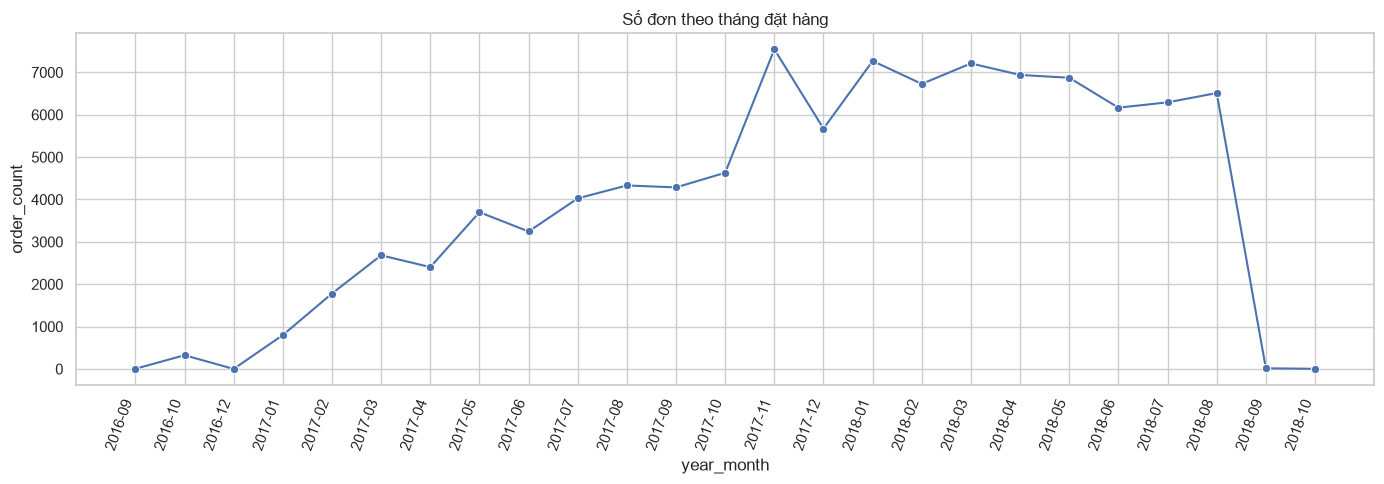

,all_orders,orders_with_items,orders_with_payments,orders_with_reviews,delivered_orders,canceled_orders
0,99441,98666,99440,98167,96478,625


In [7]:
coverage = qdf("""
SELECT
  (SELECT COUNT(*) FROM fact_orders) AS order_rows,
  (SELECT COUNT(DISTINCT order_id) FROM fact_orders) AS distinct_orders,
  (SELECT MIN(order_purchase_timestamp) FROM fact_orders) AS first_purchase,
  (SELECT MAX(order_purchase_timestamp) FROM fact_orders) AS last_purchase,
  (SELECT COUNT(*) FROM dim_customer) AS customers,
  (SELECT COUNT(*) FROM dim_product) AS products,
  (SELECT COUNT(*) FROM dim_seller) AS sellers,
  (SELECT COUNT(*) FROM dim_category) AS categories,
  (SELECT COUNT(*) FROM fact_order_items) AS item_rows,
  (SELECT COUNT(*) FROM fact_payments) AS payment_rows,
  (SELECT COUNT(*) FROM fact_reviews) AS review_rows
""")
display(coverage)

monthly_orders = qdf("""
SELECT d.year, d.month, MIN(d.date) AS month_start,
       COUNT(DISTINCT o.order_key) AS order_count
FROM fact_orders o
JOIN dim_date d ON d.date_key=o.purchase_date_key
GROUP BY d.year, d.month
ORDER BY d.year, d.month
""")
monthly_orders["year_month"] = pd.to_datetime(monthly_orders["month_start"]).dt.to_period("M").astype(str)
display(monthly_orders)

plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly_orders, x="year_month", y="order_count", marker="o")
plt.xticks(rotation=70, ha="right")
plt.title("Số đơn theo tháng đặt hàng")
plt.tight_layout()
plt.show()

display(qdf("""
SELECT
 (SELECT COUNT(*) FROM fact_orders) AS all_orders,
 (SELECT COUNT(DISTINCT order_key) FROM fact_order_items) AS orders_with_items,
 (SELECT COUNT(DISTINCT order_key) FROM fact_payments) AS orders_with_payments,
 (SELECT COUNT(DISTINCT order_key) FROM fact_reviews) AS orders_with_reviews,
 (SELECT COUNT(*) FROM fact_orders WHERE is_delivered=1) AS delivered_orders,
 (SELECT COUNT(*) FROM fact_orders WHERE is_canceled=1) AS canceled_orders
"""))

# Phần 02 — Data Quality Assessment

Các cell chỉ kiểm tra và báo cáo, không sửa dữ liệu trong DW.

## 2.1. NULL và tỷ lệ NULL

,table,column,row_count,null_count,null_pct
24,dim_product,product_name_length,32951,32951,100.000
25,dim_product,product_description_length,32951,32951,100.000
26,dim_product,product_photos_qty,32951,32951,100.000
79,fact_reviews,review_comment_title,98410,86893,88.297
80,fact_reviews,review_comment_message,98410,57752,58.685
81,fact_reviews,review_creation_date,98410,3870,3.933
82,fact_reviews,review_answer_timestamp,98410,3824,3.886
49,fact_orders,order_delivered_customer_date,99441,2965,2.982
51,fact_orders,delivery_days,99441,2965,2.982
53,fact_orders,delivery_delay_days,99441,2965,2.982


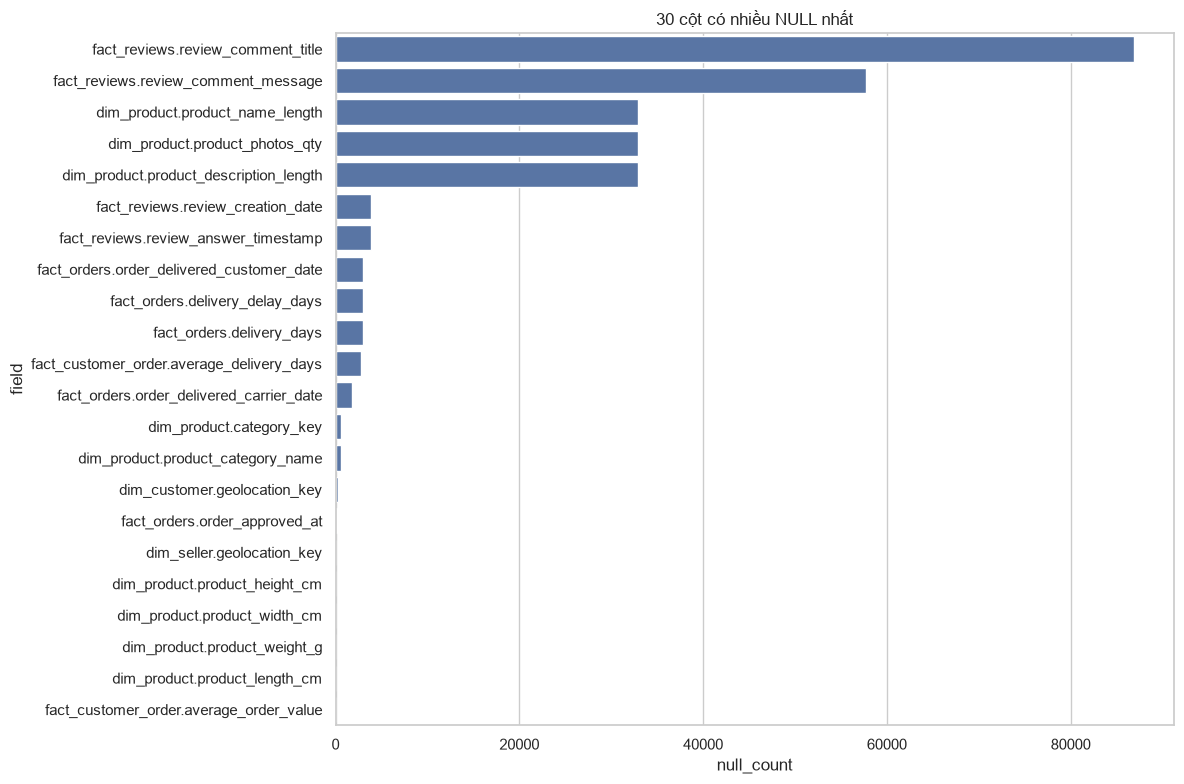

In [8]:
null_rows = []
for table in TABLES:
    cols = schema_df.loc[schema_df["TABLE_NAME"] == table, "COLUMN_NAME"].tolist()
    for col in cols:
        r = qdf(f"""
            SELECT COUNT(*) AS n_rows,
                   SUM(CASE WHEN `{col}` IS NULL THEN 1 ELSE 0 END) AS n_null
            FROM `{table}`
        """).iloc[0]
        n, z = int(r["n_rows"]), int(r["n_null"] or 0)
        null_rows.append({"table": table, "column": col, "row_count": n,
                          "null_count": z, "null_pct": 100*z/n if n else np.nan})
null_df = pd.DataFrame(null_rows)
display(null_df.sort_values(["null_pct", "null_count"], ascending=False).head(50))

null_plot = null_df[null_df["null_count"] > 0].sort_values("null_count", ascending=False).head(30).copy()
if not null_plot.empty:
    null_plot["field"] = null_plot["table"] + "." + null_plot["column"]
    plt.figure(figsize=(12, 8))
    sns.barplot(data=null_plot, y="field", x="null_count")
    plt.title("30 cột có nhiều NULL nhất")
    plt.tight_layout()
    plt.show()

## 2.2. Tính duy nhất của khóa nghiệp vụ

In [9]:
unique_checks = [
    ("dim_geolocation", "zip_code_prefix"),
    ("dim_category", "product_category_name"),
    ("dim_customer", "customer_unique_id"),
    ("dim_seller", "seller_id"),
    ("dim_product", "product_id"),
    ("dim_date", "date"),
    ("fact_orders", "order_id"),
    ("fact_reviews", "review_id")
]
unique_results = []
for table, col in unique_checks:
    r = qdf(f"SELECT COUNT(*) n, COUNT(`{col}`) nn, COUNT(DISTINCT `{col}`) nd FROM `{table}`").iloc[0]
    unique_results.append({"table": table, "key": col, "rows": int(r.n),
                           "nonnull": int(r.nn), "distinct": int(r.nd),
                           "duplicate_excess": int(r.nn-r.nd)})

for table, key_expr in [
    ("fact_order_items", "CONCAT_WS('|', order_id, order_item_id)"),
    ("fact_payments", "CONCAT_WS('|', order_id, payment_sequential)")
]:
    r = qdf(f"SELECT COUNT(*) n, COUNT(DISTINCT {key_expr}) nd FROM `{table}`").iloc[0]
    unique_results.append({"table": table, "key": key_expr, "rows": int(r.n),
                           "nonnull": int(r.n), "distinct": int(r.nd),
                           "duplicate_excess": int(r.n-r.nd)})
display(pd.DataFrame(unique_results))

,table,key,rows,nonnull,distinct,duplicate_excess
0,dim_geolocation,zip_code_prefix,19015,19015,19015,0
1,dim_category,product_category_name,71,71,71,0
2,dim_customer,customer_unique_id,96096,96096,96096,0
3,dim_seller,seller_id,3095,3095,3095,0
4,dim_product,product_id,32951,32951,32951,0
5,dim_date,date,774,774,774,0
6,fact_orders,order_id,99441,99441,99441,0
7,fact_reviews,review_id,98410,98410,98410,0
8,fact_order_items,"CONCAT_WS('|', order_id, order_item_id)",112650,112650,112650,0
9,fact_payments,"CONCAT_WS('|', order_id, payment_sequential)",103886,103886,103886,0


## 2.3. Quy tắc hợp lệ và nhất quán

,rule,violations
0,review_score_outside_1_5,0
1,negative_price,0
2,negative_freight,0
3,negative_payment,0
4,delivery_before_purchase,0
5,delivered_flag_but_no_delivery_date,8
6,delay_days_mismatch_with_DATEDIFF,0
7,item_total_differs_price_plus_freight,0


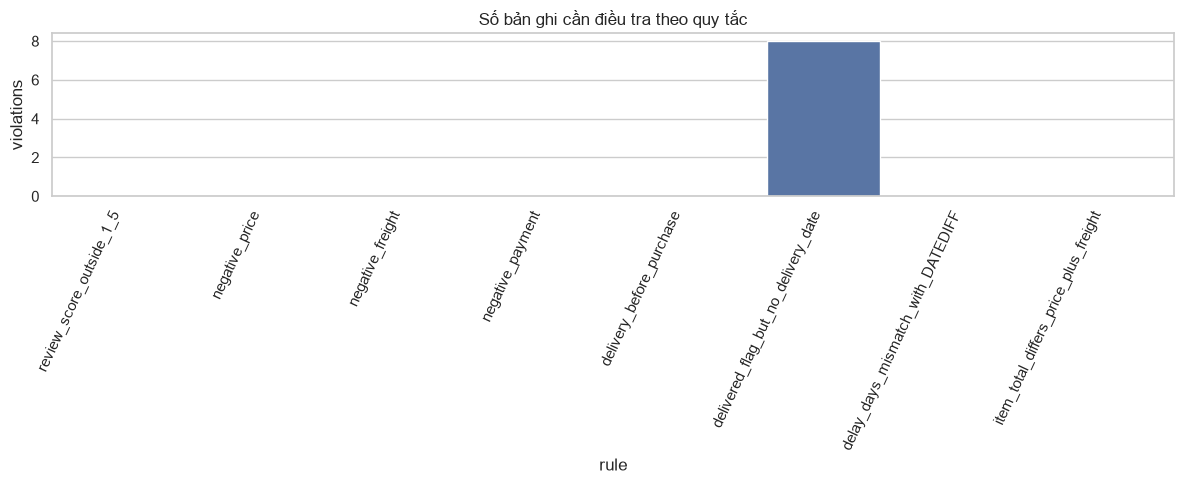

In [10]:
quality_rules = {
    "review_score_outside_1_5": """SELECT COUNT(*) n FROM fact_reviews WHERE review_score IS NOT NULL AND review_score NOT BETWEEN 1 AND 5""",
    "negative_price": """SELECT COUNT(*) n FROM fact_order_items WHERE price < 0""",
    "negative_freight": """SELECT COUNT(*) n FROM fact_order_items WHERE freight_value < 0""",
    "negative_payment": """SELECT COUNT(*) n FROM fact_payments WHERE payment_value < 0""",
    "delivery_before_purchase": """SELECT COUNT(*) n FROM fact_orders WHERE order_delivered_customer_date < order_purchase_timestamp""",
    "delivered_flag_but_no_delivery_date": """SELECT COUNT(*) n FROM fact_orders WHERE is_delivered=1 AND order_delivered_customer_date IS NULL""",
    "delay_days_mismatch_with_DATEDIFF": """SELECT COUNT(*) n FROM fact_orders WHERE order_delivered_customer_date IS NOT NULL AND order_estimated_delivery_date IS NOT NULL AND delivery_delay_days IS NOT NULL AND DATEDIFF(order_delivered_customer_date, order_estimated_delivery_date) <> delivery_delay_days""",
    "item_total_differs_price_plus_freight": """SELECT COUNT(*) n FROM fact_order_items WHERE item_total IS NOT NULL AND price IS NOT NULL AND freight_value IS NOT NULL AND ABS(item_total-(price+freight_value))>0.01"""
}
rule_results = []
for name, query in quality_rules.items():
    rule_results.append({"rule": name, "violations": int(qdf(query).loc[0, "n"])})
rule_df = pd.DataFrame(rule_results)
display(rule_df)

plt.figure(figsize=(12, 5))
sns.barplot(data=rule_df, x="rule", y="violations")
plt.xticks(rotation=65, ha="right")
plt.title("Số bản ghi cần điều tra theo quy tắc")
plt.tight_layout()
plt.show()

**Lưu ý:** `item_total = price + freight_value` và phép kiểm tra `delivery_delay_days = DATEDIFF(...)` là các phép đối chiếu giả định. Nếu ETL dùng công thức hoặc quy ước khác, hãy điều chỉnh theo code ETL trước khi coi kết quả là vi phạm.

## 2.4. Khóa ngoại và đối soát nội bộ

In [11]:
orphan_checks = {
    "customer_to_geolocation": """SELECT COUNT(*) n FROM dim_customer c LEFT JOIN dim_geolocation g ON c.geolocation_key=g.geolocation_key WHERE c.geolocation_key IS NOT NULL AND g.geolocation_key IS NULL""",
    "seller_to_geolocation": """SELECT COUNT(*) n FROM dim_seller s LEFT JOIN dim_geolocation g ON s.geolocation_key=g.geolocation_key WHERE s.geolocation_key IS NOT NULL AND g.geolocation_key IS NULL""",
    "product_to_category": """SELECT COUNT(*) n FROM dim_product p LEFT JOIN dim_category c ON p.category_key=c.category_key WHERE p.category_key IS NOT NULL AND c.category_key IS NULL""",
    "orders_to_customer": """SELECT COUNT(*) n FROM fact_orders f LEFT JOIN dim_customer d ON f.customer_key=d.customer_key WHERE d.customer_key IS NULL""",
    "orders_to_date": """SELECT COUNT(*) n FROM fact_orders f LEFT JOIN dim_date d ON f.purchase_date_key=d.date_key WHERE d.date_key IS NULL""",
    "items_to_order": """SELECT COUNT(*) n FROM fact_order_items i LEFT JOIN fact_orders o ON i.order_key=o.order_key WHERE o.order_key IS NULL""",
    "items_to_product": """SELECT COUNT(*) n FROM fact_order_items i LEFT JOIN dim_product p ON i.product_key=p.product_key WHERE p.product_key IS NULL""",
    "items_to_seller": """SELECT COUNT(*) n FROM fact_order_items i LEFT JOIN dim_seller s ON i.seller_key=s.seller_key WHERE s.seller_key IS NULL""",
    "payments_to_order": """SELECT COUNT(*) n FROM fact_payments p LEFT JOIN fact_orders o ON p.order_key=o.order_key WHERE o.order_key IS NULL""",
    "reviews_to_order": """SELECT COUNT(*) n FROM fact_reviews r LEFT JOIN fact_orders o ON r.order_key=o.order_key WHERE o.order_key IS NULL""",
    "customer_fact_to_customer": """SELECT COUNT(*) n FROM fact_customer_order f LEFT JOIN dim_customer c ON f.customer_key=c.customer_key WHERE c.customer_key IS NULL"""
}
display(pd.DataFrame([{"relationship": k, "orphan_rows": int(qdf(v).loc[0, "n"])} for k, v in orphan_checks.items()]))

display(qdf("""
SELECT
 (SELECT COUNT(*) FROM fact_orders) AS orders_rows,
 (SELECT COUNT(DISTINCT order_id) FROM fact_orders) AS distinct_order_ids,
 (SELECT COUNT(*) FROM fact_order_items) AS item_rows,
 (SELECT COUNT(DISTINCT CONCAT_WS('|', order_id, order_item_id)) FROM fact_order_items) AS distinct_item_keys,
 (SELECT COUNT(*) FROM fact_payments) AS payment_rows,
 (SELECT COUNT(DISTINCT CONCAT_WS('|', order_id, payment_sequential)) FROM fact_payments) AS distinct_payment_keys,
 (SELECT COUNT(*) FROM fact_reviews) AS review_rows,
 (SELECT COUNT(DISTINCT review_id) FROM fact_reviews) AS distinct_review_ids,
 (SELECT COUNT(*) FROM fact_customer_order) AS customer_order_rows,
 (SELECT COUNT(DISTINCT customer_key) FROM fact_customer_order) AS distinct_customer_keys
"""))

,relationship,orphan_rows
0,customer_to_geolocation,0
1,seller_to_geolocation,0
2,product_to_category,0
3,orders_to_customer,0
4,orders_to_date,0
5,items_to_order,0
6,items_to_product,0
7,items_to_seller,0
8,payments_to_order,0
9,reviews_to_order,0


,orders_rows,distinct_order_ids,item_rows,distinct_item_keys,payment_rows,distinct_payment_keys,review_rows,distinct_review_ids,customer_order_rows,distinct_customer_keys
0,99441,99441,112650,112650,103886,103886,98410,98410,96096,96096


# Phần 03 — Exploratory Data Analysis

## 3.1. Phân phối đơn hàng và trạng thái

,order_status,orders,pct
0,delivered,96478,97.020
1,shipped,1107,1.113
2,canceled,625,0.629
3,unavailable,609,0.612
4,invoiced,314,0.316
5,processing,301,0.303
6,created,5,0.005
7,approved,2,0.002


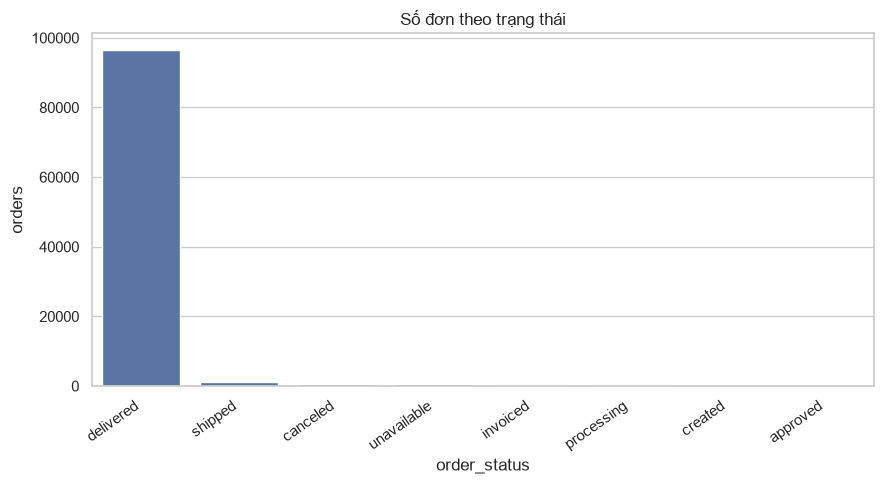

,hours_to_approval
count,"99,281.000"
mean,10.064
std,25.983
min,0.000
50%,0.000
90%,34.000
95%,48.000
99%,90.000
max,"4,509.000"


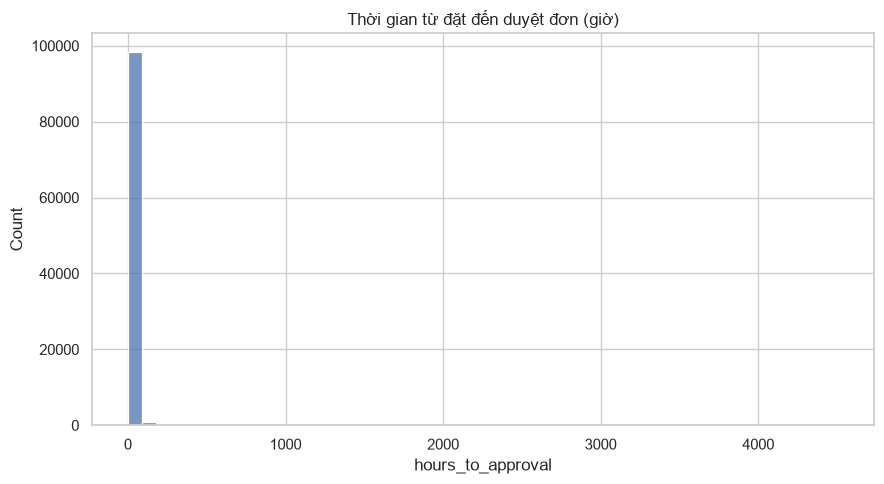

In [12]:
status_df = qdf("""
SELECT COALESCE(order_status, '(NULL)') AS order_status, COUNT(*) AS orders,
       100.0*COUNT(*)/(SELECT COUNT(*) FROM fact_orders) AS pct
FROM fact_orders
GROUP BY COALESCE(order_status, '(NULL)')
ORDER BY orders DESC
""")
display(status_df)
plt.figure(figsize=(9, 5))
sns.barplot(data=status_df, x="order_status", y="orders")
plt.xticks(rotation=35, ha="right")
plt.title("Số đơn theo trạng thái")
plt.tight_layout()
plt.show()

approval = qdf("""
SELECT TIMESTAMPDIFF(HOUR, order_purchase_timestamp, order_approved_at) AS hours_to_approval
FROM fact_orders
WHERE order_purchase_timestamp IS NOT NULL AND order_approved_at IS NOT NULL
  AND order_approved_at >= order_purchase_timestamp
""")
display(approval.describe(percentiles=[.5, .9, .95, .99]))
plt.figure(figsize=(9, 5))
sns.histplot(approval["hours_to_approval"], bins=50)
plt.title("Thời gian từ đặt đến duyệt đơn (giờ)")
plt.tight_layout()
plt.show()

## 3.2. Giá sản phẩm, phí vận chuyển và thanh toán

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,"112,650.000",120.654,183.634,0.850,9.990,17.000,39.900,74.990,134.900,349.900,890.000,"6,735.000"
freight_value,"112,650.000",19.990,15.806,0.000,4.420,7.780,13.080,16.260,21.150,45.120,84.520,409.680
item_total,"112,650.000",140.644,190.724,6.080,20.860,30.020,55.220,92.320,157.938,378.959,923.216,"6,929.310"


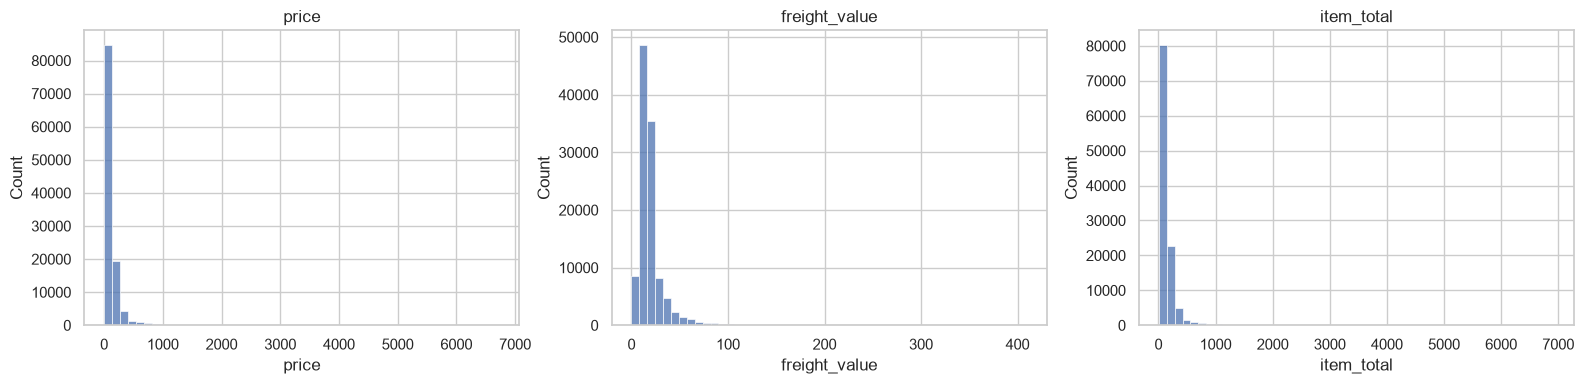

,payment_type,payment_records,orders_using_type,total_payment_value,mean_payment_record_value,mean_installments
0,credit_card,76795,76505,"12,542,084.190",163.319,3.507
1,boleto,19784,19784,"2,869,361.270",145.034,1.000
2,voucher,5775,3866,"379,436.870",65.703,1.000
3,debit_card,1529,1528,"217,989.790",142.570,1.000
4,not_defined,3,3,0.000,0.000,1.000


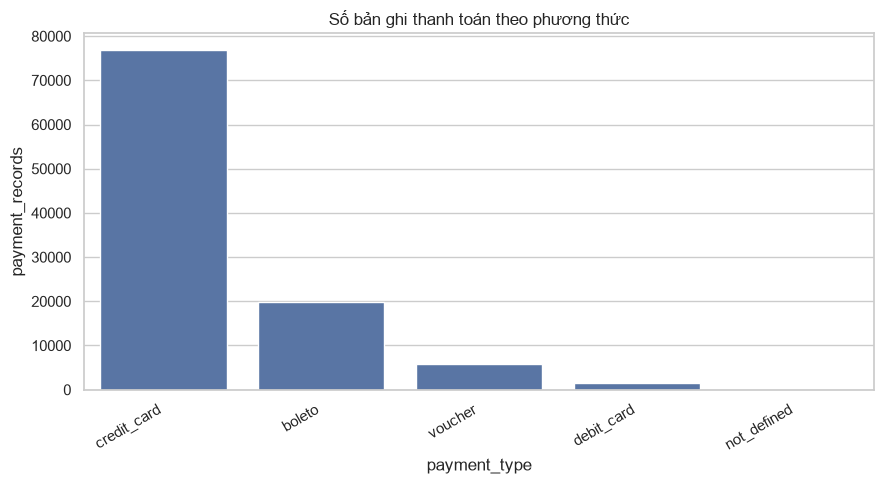

,payment_installments,payment_records
0,0,2
1,1,52546
2,2,12413
3,3,10461
4,4,7098
5,5,5239
6,6,3920
7,7,1626
8,8,4268
9,9,644


In [13]:
items_num = qdf("SELECT price, freight_value, item_total FROM fact_order_items")
display(items_num.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["price", "freight_value", "item_total"]):
    sns.histplot(items_num[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

payment_summary = qdf("""
SELECT COALESCE(payment_type, '(NULL)') AS payment_type,
       COUNT(*) AS payment_records,
       COUNT(DISTINCT order_key) AS orders_using_type,
       SUM(payment_value) AS total_payment_value,
       AVG(payment_value) AS mean_payment_record_value,
       AVG(payment_installments) AS mean_installments
FROM fact_payments
GROUP BY COALESCE(payment_type, '(NULL)')
ORDER BY payment_records DESC
""")
display(payment_summary)
plt.figure(figsize=(9, 5))
sns.barplot(data=payment_summary, x="payment_type", y="payment_records")
plt.xticks(rotation=30, ha="right")
plt.title("Số bản ghi thanh toán theo phương thức")
plt.tight_layout()
plt.show()

installments = qdf("""
SELECT payment_installments, COUNT(*) AS payment_records
FROM fact_payments
WHERE payment_installments IS NOT NULL
GROUP BY payment_installments
ORDER BY payment_installments
""")
display(installments)

## 3.3. Khách hàng, sản phẩm, danh mục và seller

,state,customers
0,SP,40297
1,RJ,12376
2,MG,11255
3,RS,5277
4,PR,4882
5,SC,3528
6,BA,3276
7,DF,2073
8,ES,1963
9,GO,1951


,category,products
0,bed_bath_table,3029
1,sports_leisure,2867
2,furniture_decor,2657
3,health_beauty,2444
4,housewares,2335
5,auto,1900
6,computers_accessories,1639
7,toys,1411
8,watches_gifts,1329
9,telephony,1134


,state,sellers
0,SP,1849
1,PR,349
2,MG,244
3,SC,190
4,RJ,171
5,RS,129
6,GO,40
7,DF,30
8,ES,23
9,BA,19


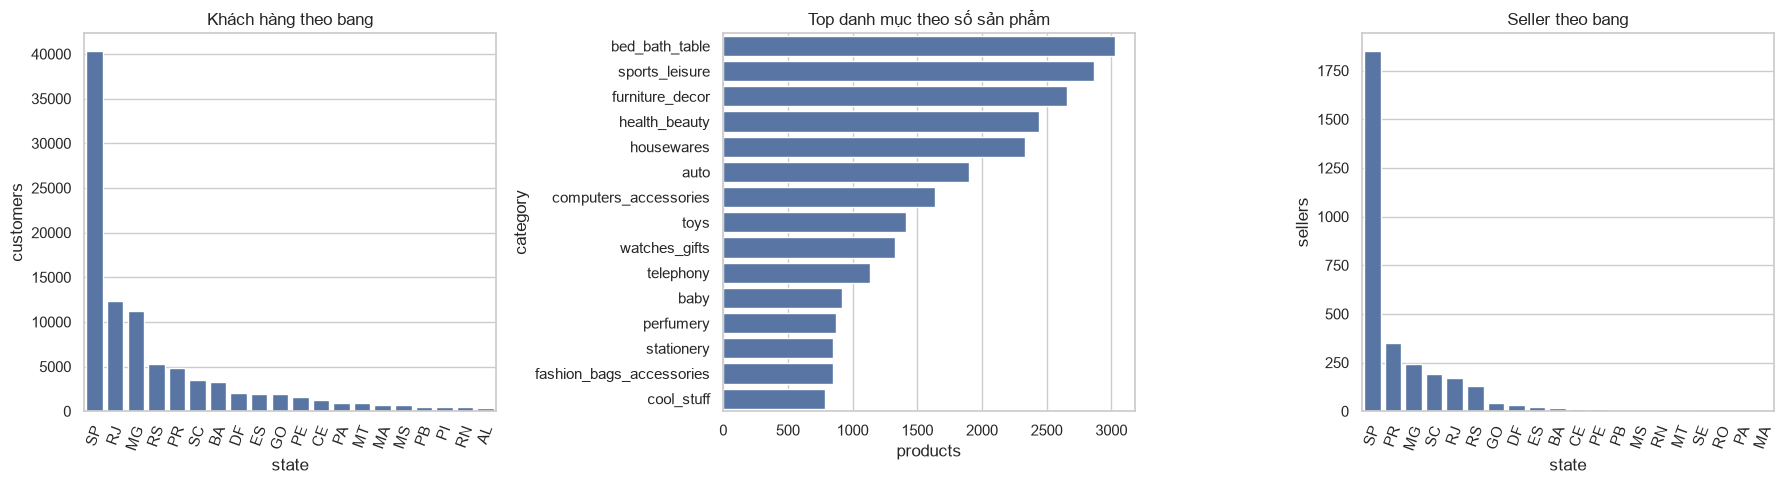

,count,mean,std,min,1%,50%,95%,99%,max
product_weight_g,"32,949.000","2,276.472","4,282.039",0.000,60.000,700.000,"10,850.000","22,538.000","40,425.000"
product_length_cm,"32,949.000",30.815,16.914,7.000,16.000,25.000,65.000,100.000,105.000
product_height_cm,"32,949.000",16.938,13.638,2.000,2.000,13.000,44.000,69.000,105.000
product_width_cm,"32,949.000",23.197,12.079,6.000,11.000,20.000,47.000,63.000,118.000


In [14]:
customer_state = qdf("""
SELECT COALESCE(state, '(NULL)') state, COUNT(*) customers
FROM dim_customer GROUP BY COALESCE(state, '(NULL)') ORDER BY customers DESC LIMIT 20
""")
category_products = qdf("""
SELECT COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)') category,
       COUNT(*) products
FROM dim_product p LEFT JOIN dim_category c ON c.category_key=p.category_key
GROUP BY COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)')
ORDER BY products DESC LIMIT 25
""")
seller_state = qdf("""
SELECT COALESCE(state, '(NULL)') state, COUNT(*) sellers
FROM dim_seller GROUP BY COALESCE(state, '(NULL)') ORDER BY sellers DESC LIMIT 20
""")
display(customer_state)
display(category_products)
display(seller_state)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=customer_state, x="state", y="customers", ax=axes[0])
axes[0].tick_params(axis="x", rotation=70)
axes[0].set_title("Khách hàng theo bang")
sns.barplot(data=category_products.head(15), y="category", x="products", ax=axes[1])
axes[1].set_title("Top danh mục theo số sản phẩm")
sns.barplot(data=seller_state, x="state", y="sellers", ax=axes[2])
axes[2].tick_params(axis="x", rotation=70)
axes[2].set_title("Seller theo bang")
plt.tight_layout()
plt.show()

product_attrs = qdf("""
SELECT product_weight_g, product_length_cm, product_height_cm, product_width_cm,
       product_photos_qty, product_name_length, product_description_length
FROM dim_product
""")
display(product_attrs.describe(percentiles=[.01, .5, .95, .99]).T)

## 3.4. Phân tích thời gian — số đơn, doanh thu và AOV

In [15]:
# Doanh thu = SUM(price) theo dòng hàng. Mặc định gồm mọi trạng thái.
# Đổi thành ["delivered"] nếu báo cáo chỉ muốn đơn đã giao.
STATUS_FILTER = None

where_status = ""
params = {}
if STATUS_FILTER:
    ph = ", ".join([f":s{i}" for i in range(len(STATUS_FILTER))])
    where_status = f"WHERE o.order_status IN ({ph})"
    params = {f"s{i}": v for i, v in enumerate(STATUS_FILTER)}

monthly_sales = qdf(f"""
SELECT d.year, d.month, MIN(d.date) AS month_start,
       COUNT(DISTINCT o.order_key) AS total_orders,
       SUM(i.price) AS product_revenue,
       SUM(i.freight_value) AS freight_revenue,
       SUM(i.price + COALESCE(i.freight_value,0)) AS product_plus_freight,
       SUM(i.price)/NULLIF(COUNT(DISTINCT o.order_key),0) AS product_revenue_per_order
FROM fact_orders o
JOIN dim_date d ON d.date_key=o.purchase_date_key
JOIN fact_order_items i ON i.order_key=o.order_key
{where_status}
GROUP BY d.year, d.month
ORDER BY d.year, d.month
""", params)
monthly_sales["year_month"] = pd.to_datetime(monthly_sales["month_start"]).dt.to_period("M").astype(str)
monthly_sales["revenue_mom_pct"] = monthly_sales["product_revenue"].pct_change()*100
monthly_sales["orders_mom_pct"] = monthly_sales["total_orders"].pct_change()*100
monthly_sales["aov_mom_pct"] = monthly_sales["product_revenue_per_order"].pct_change()*100
display(monthly_sales)

,year,month,month_start,total_orders,product_revenue,freight_revenue,product_plus_freight,product_revenue_per_order,year_month,revenue_mom_pct,orders_mom_pct,aov_mom_pct
0,2016,9,2016-09-04,3,267.360,87.390,354.750,89.120,2016-09,NaN,NaN,NaN
1,2016,10,2016-10-02,308,"49,507.660","7,301.180","56,808.840",160.739,2016-10,"18,417.228","10,166.667",80.363
2,2016,12,2016-12-23,1,10.900,8.720,19.620,10.900,2016-12,-99.978,-99.675,-93.219
3,2017,1,2017-01-05,789,"120,312.870","16,875.620","137,188.490",152.488,2017-01,"1,103,687.798","78,800.000","1,298.971"
4,2017,2,2017-02-01,1733,"247,303.020","38,977.600","286,280.620",142.702,2017-02,105.550,119.645,-6.417
5,2017,3,2017-03-01,2641,"374,344.300","57,704.290","432,048.590",141.743,2017-03,51.371,52.395,-0.672
6,2017,4,2017-04-01,2391,"359,927.230","52,495.010","412,422.240",150.534,2017-04,-3.851,-9.466,6.202
7,2017,5,2017-05-01,3660,"506,071.140","80,119.810","586,190.950",138.271,2017-05,40.604,53.074,-8.147
8,2017,6,2017-06-01,3217,"433,038.600","69,924.440","502,963.040",134.609,2017-06,-14.431,-12.104,-2.648
9,2017,7,2017-07-01,3969,"498,031.480","86,940.140","584,971.620",125.480,2017-07,15.009,23.376,-6.782


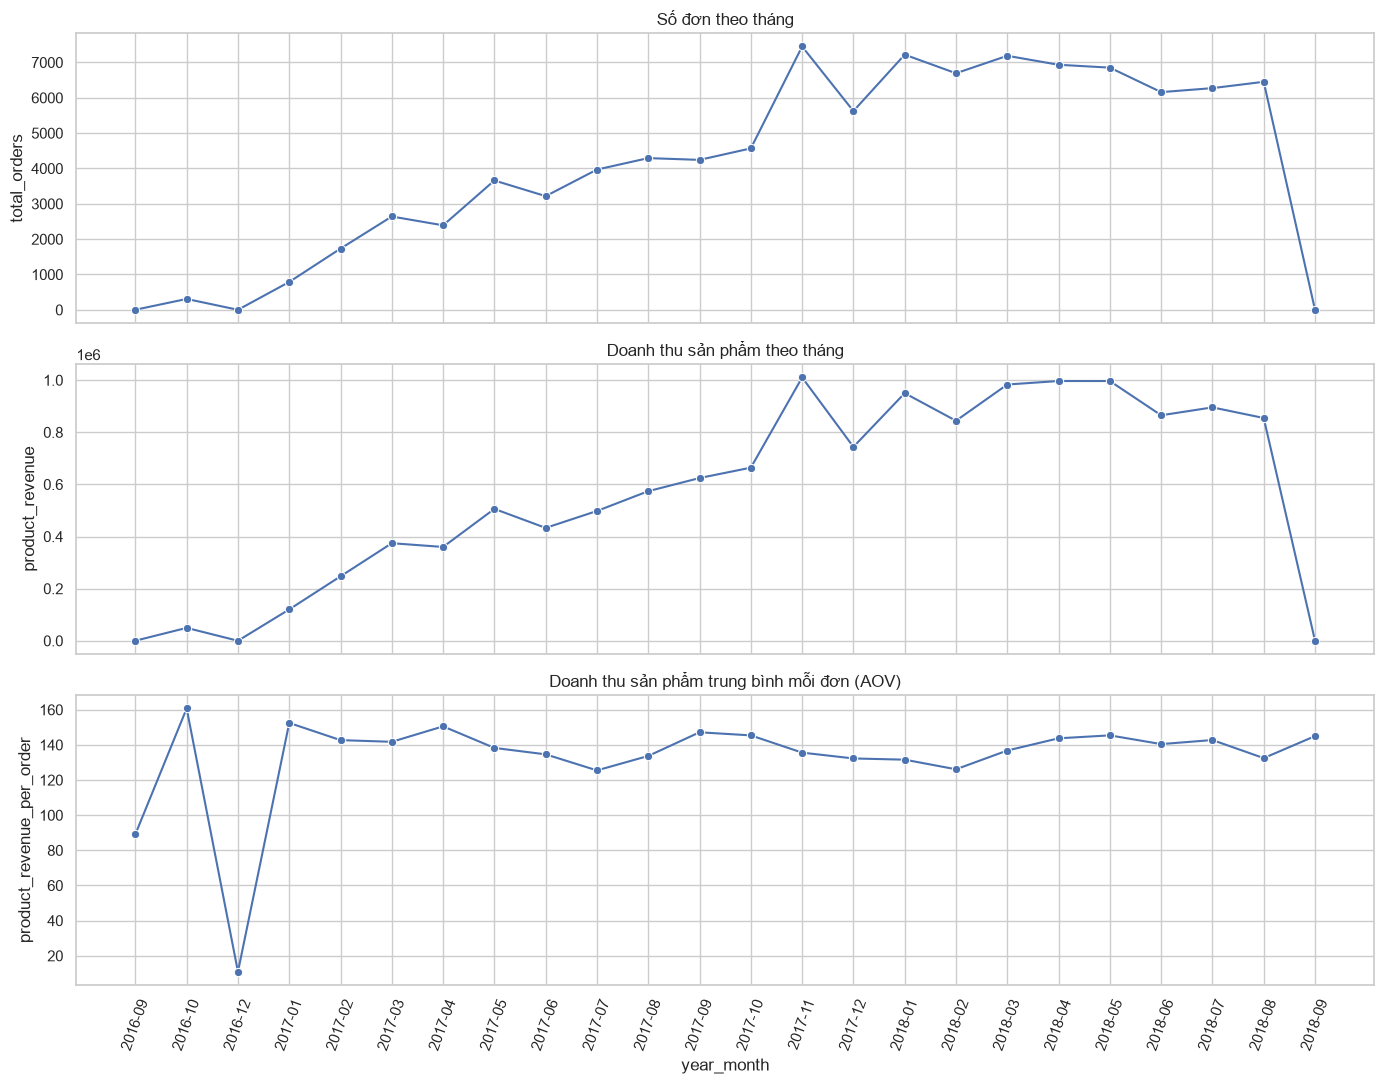

,year_month,revenue_mom_pct,orders_mom_pct,aov_mom_pct
0,2016-09,NaN,NaN,NaN
1,2016-10,"18,417.228","10,166.667",80.363
2,2016-12,-99.978,-99.675,-93.219
3,2017-01,"1,103,687.798","78,800.000","1,298.971"
4,2017-02,105.550,119.645,-6.417
5,2017-03,51.371,52.395,-0.672
6,2017-04,-3.851,-9.466,6.202
7,2017-05,40.604,53.074,-8.147
8,2017-06,-14.431,-12.104,-2.648
9,2017-07,15.009,23.376,-6.782


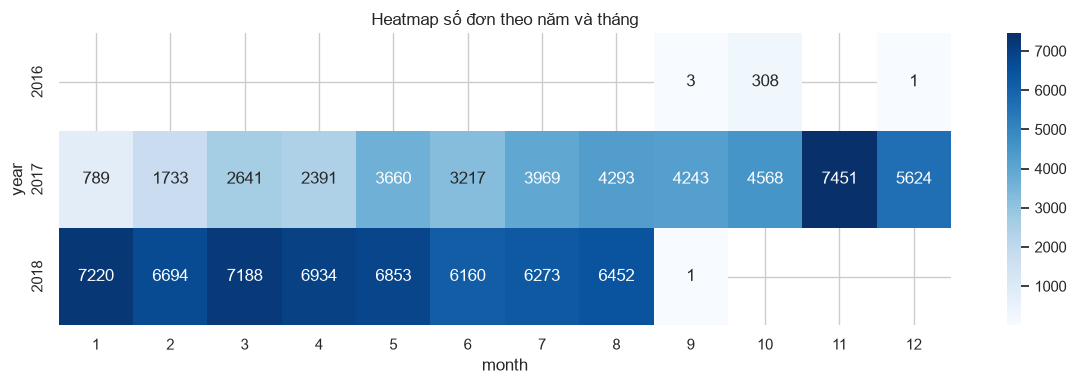

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, col, title in zip(
    axes,
    ["total_orders", "product_revenue", "product_revenue_per_order"],
    ["Số đơn theo tháng", "Doanh thu sản phẩm theo tháng", "Doanh thu sản phẩm trung bình mỗi đơn (AOV)"]
):
    sns.lineplot(data=monthly_sales, x="year_month", y=col, marker="o", ax=ax)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

display(monthly_sales[["year_month", "revenue_mom_pct", "orders_mom_pct", "aov_mom_pct"]])

pivot = monthly_sales.pivot(index="year", columns="month", values="total_orders")
plt.figure(figsize=(12, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")
plt.title("Heatmap số đơn theo năm và tháng")
plt.tight_layout()
plt.show()

## 3.5. Giao hàng và độ trễ

,count,mean,std,min,50%,90%,95%,99%,max
delivery_days,"96,476.000",12.497,9.555,0.000,10.000,23.000,29.000,46.000,210.000
estimated_delivery_days,"96,476.000",24.374,8.761,3.000,24.000,35.000,39.000,51.000,156.000
delivery_delay_days,"96,476.000",-11.877,10.184,-147.000,-12.000,-2.000,3.000,18.000,188.000


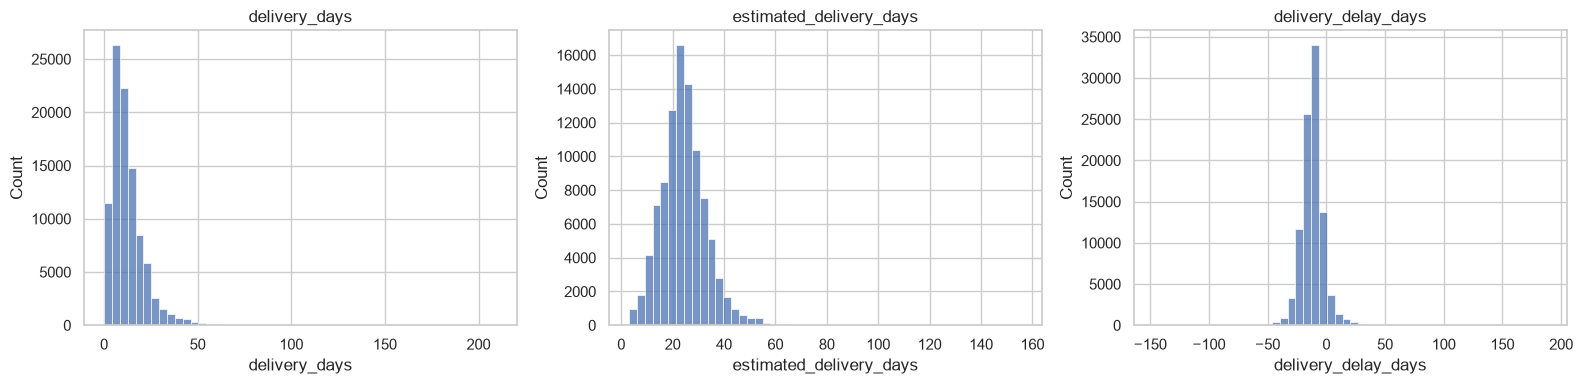

,delivery_group,orders
0,Early,88649
1,Late,6535
2,On time,1292


In [17]:
delivery = qdf("""
SELECT order_key, order_status, delivery_days, estimated_delivery_days, delivery_delay_days,
       order_delivered_customer_date, order_estimated_delivery_date
FROM fact_orders
WHERE order_delivered_customer_date IS NOT NULL
""")
display(delivery[["delivery_days", "estimated_delivery_days", "delivery_delay_days"]]
        .describe(percentiles=[.5, .9, .95, .99]).T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["delivery_days", "estimated_delivery_days", "delivery_delay_days"]):
    sns.histplot(delivery[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

delivery_groups = qdf("""
SELECT CASE WHEN delivery_delay_days < 0 THEN 'Early'
            WHEN delivery_delay_days = 0 THEN 'On time'
            WHEN delivery_delay_days > 0 THEN 'Late'
            ELSE 'Unknown' END AS delivery_group,
       COUNT(*) orders
FROM fact_orders
WHERE order_delivered_customer_date IS NOT NULL
GROUP BY delivery_group
""")
display(delivery_groups)

## 3.6. Đánh giá

,review_score,review_records
0,1,11282
1,2,3114
2,3,8097
3,4,19007
4,5,56910


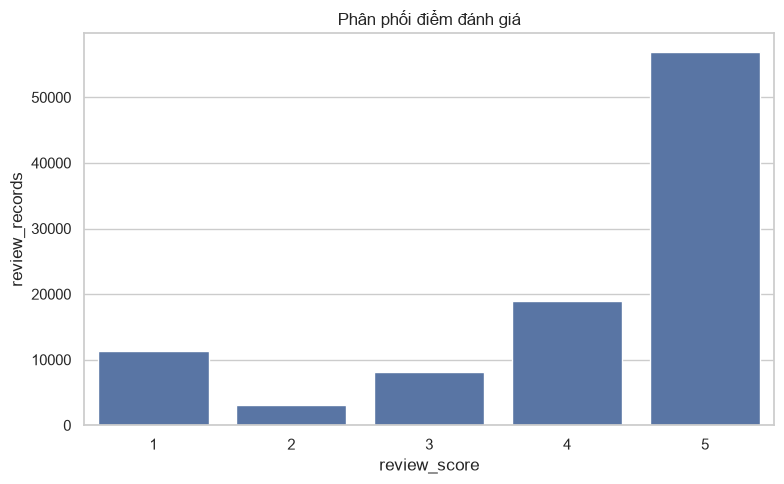

In [18]:
review_scores = qdf("""
SELECT review_score, COUNT(*) AS review_records
FROM fact_reviews
WHERE review_score IS NOT NULL
GROUP BY review_score ORDER BY review_score
""")
display(review_scores)
plt.figure(figsize=(8, 5))
sns.barplot(data=review_scores, x="review_score", y="review_records")
plt.title("Phân phối điểm đánh giá")
plt.tight_layout()
plt.show()

# Phần 04 — Business Analysis

## 4.1. Sales Performance — danh mục và sản phẩm

,category,orders,item_rows,product_revenue,freight_revenue
0,health_beauty,8647,9465,"1,233,131.720","178,957.810"
1,watches_gifts,5495,5859,"1,166,176.980","98,156.140"
2,bed_bath_table,9272,10953,"1,023,434.760","201,774.500"
3,sports_leisure,7530,8431,"954,852.550","163,404.360"
4,computers_accessories,6530,7644,"888,724.610","143,999.160"
5,furniture_decor,6307,8160,"711,927.690","168,402.230"
6,housewares,5743,6795,"615,628.690","142,763.560"
7,cool_stuff,3559,3718,"610,204.100","81,476.790"
8,auto,3810,4140,"578,966.650","90,488.100"
9,toys,3804,4030,"471,286.480","75,774.580"


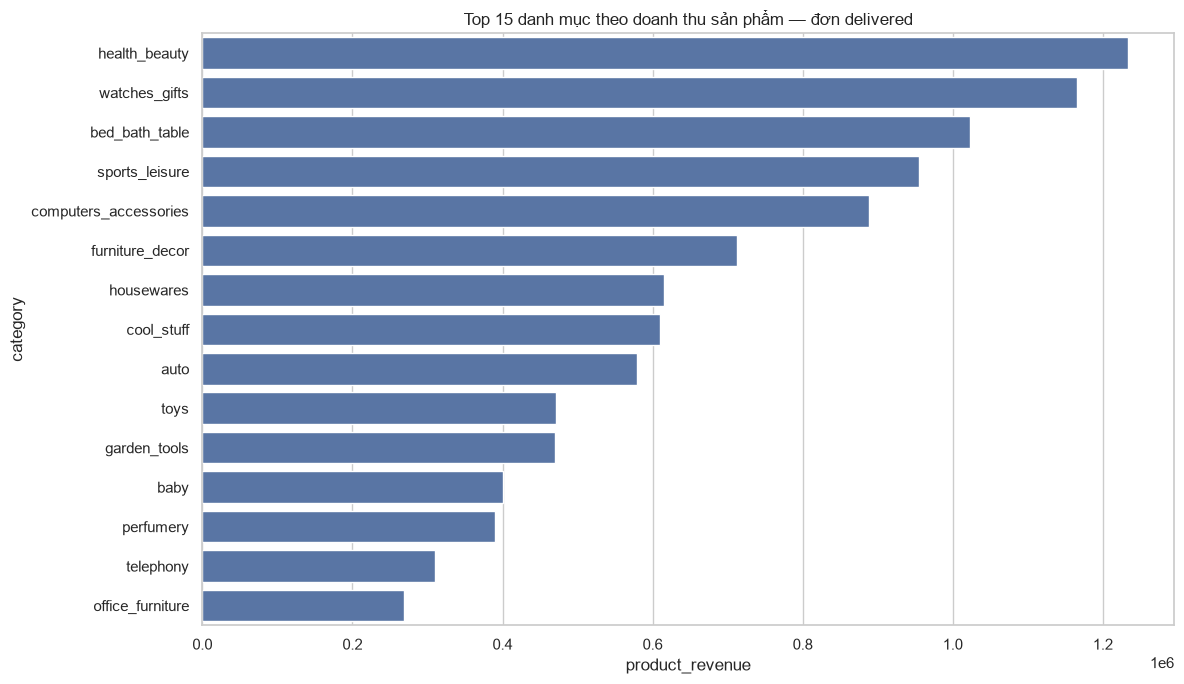

,product_id,category,item_rows,orders,product_revenue
0,bb50f2e236e5eea0100680137654686c,health_beauty,194,186,"63,560.000"
1,6cdd53843498f92890544667809f1595,health_beauty,153,148,"53,652.300"
2,d6160fb7873f184099d9bc95e30376af,computers,33,33,"45,949.350"
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,332,313,"45,620.560"
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,477,456,"42,049.660"
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,272,253,"40,782.800"
6,25c38557cf793876c5abdd5931f922db,baby,38,38,"38,907.320"
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,63,"37,733.900"
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,321,304,"37,454.630"
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,520,425,"37,104.300"


In [19]:
category_sales = qdf("""
SELECT COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)') category,
       COUNT(DISTINCT o.order_key) orders,
       COUNT(*) item_rows,
       SUM(i.price) product_revenue,
       SUM(i.freight_value) freight_revenue
FROM fact_order_items i
JOIN fact_orders o ON o.order_key=i.order_key
JOIN dim_product p ON p.product_key=i.product_key
LEFT JOIN dim_category c ON c.category_key=p.category_key
WHERE o.order_status='delivered'
GROUP BY COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)')
ORDER BY product_revenue DESC
""")
display(category_sales.head(25))
plt.figure(figsize=(12, 7))
sns.barplot(data=category_sales.head(15), y="category", x="product_revenue")
plt.title("Top 15 danh mục theo doanh thu sản phẩm — đơn delivered")
plt.tight_layout()
plt.show()

top_products = qdf("""
SELECT p.product_id,
       COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)') category,
       COUNT(*) item_rows, COUNT(DISTINCT i.order_key) orders, SUM(i.price) product_revenue
FROM fact_order_items i
JOIN fact_orders o ON o.order_key=i.order_key
JOIN dim_product p ON p.product_key=i.product_key
LEFT JOIN dim_category c ON c.category_key=p.category_key
WHERE o.order_status='delivered'
GROUP BY p.product_id, category
ORDER BY product_revenue DESC LIMIT 20
""")
display(top_products)

## 4.2. Customer Behavior — khách mua một lần và mua lại

,customer_group,customers,summed_orders,total_spent_sum,mean_total_spent,mean_customer_aov,mean_avg_delivery_days
0,One order,93099,"93,099.000","15,064,849.410",161.815,161.817,12.515
1,Repeat (2+ orders),2997,"6,342.000","944,022.710",314.989,148.501,12.269


count   96,096.000
mean         1.035
std          0.214
min          1.000
50%          1.000
90%          1.000
95%          1.000
99%          2.000
max         17.000
Name: order_count, dtype: float64

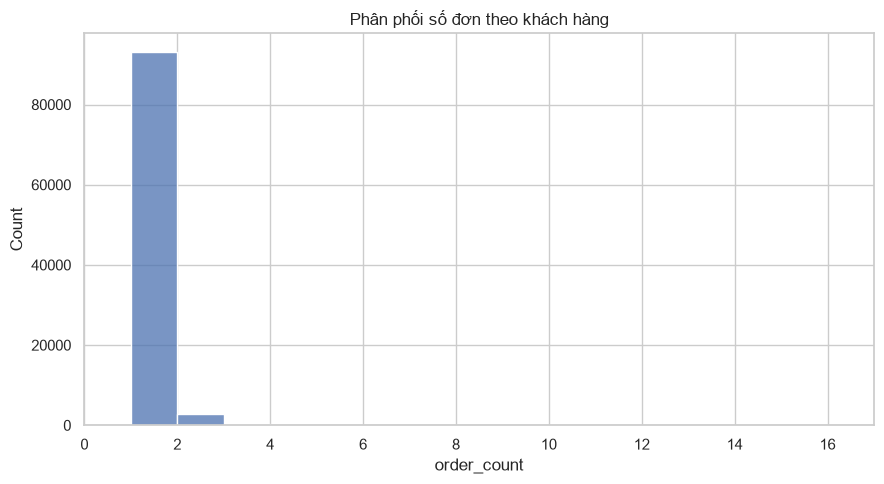

In [20]:
customer_behavior = qdf("""
SELECT CASE WHEN order_count>1 THEN 'Repeat (2+ orders)'
            WHEN order_count=1 THEN 'One order'
            ELSE 'Zero/unknown orders' END customer_group,
       COUNT(*) customers,
       SUM(COALESCE(order_count,0)) summed_orders,
       SUM(COALESCE(total_spent,0)) total_spent_sum,
       AVG(total_spent) mean_total_spent,
       AVG(average_order_value) mean_customer_aov,
       AVG(average_delivery_days) mean_avg_delivery_days
FROM fact_customer_order
GROUP BY customer_group
ORDER BY customers DESC
""")
display(customer_behavior)

customer_counts = qdf("SELECT order_count FROM fact_customer_order WHERE order_count IS NOT NULL")
display(customer_counts["order_count"].describe(percentiles=[.5,.9,.95,.99]))
plt.figure(figsize=(9, 5))
sns.histplot(customer_counts["order_count"], bins=range(1, int(customer_counts["order_count"].max())+2))
plt.xlim(0, min(20, int(customer_counts["order_count"].max())))
plt.title("Phân phối số đơn theo khách hàng")
plt.tight_layout()
plt.show()

## 4.3. Seller Performance

,seller_id,state,orders,item_rows,product_revenue,freight_revenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1124,1148,"226,987.930","20,019.130"
1,53243585a1d6dc2643021fd1853d8905,BA,348,400,"217,940.440","12,856.580"
2,4a3ca9315b744ce9f8e9374361493884,SP,1772,1949,"196,882.120","34,338.310"
3,fa1c13f2614d7b5c4749cbc52fecda94,SP,578,579,"190,917.140","9,916.360"
4,7c67e1448b00f6e969d365cea6b010ab,SP,973,1355,"186,570.050","51,236.640"
5,7e93a43ef30c4f03f38b393420bc753a,SP,319,322,"165,981.490","5,992.060"
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1311,1548,"159,816.870","24,889.910"
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1145,1155,"139,658.690","20,619.830"
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,910,1420,"138,208.560","33,716.400"
9,955fee9216a65b617aa5c0531780ce60,SP,1261,1472,"131,836.710","24,769.770"


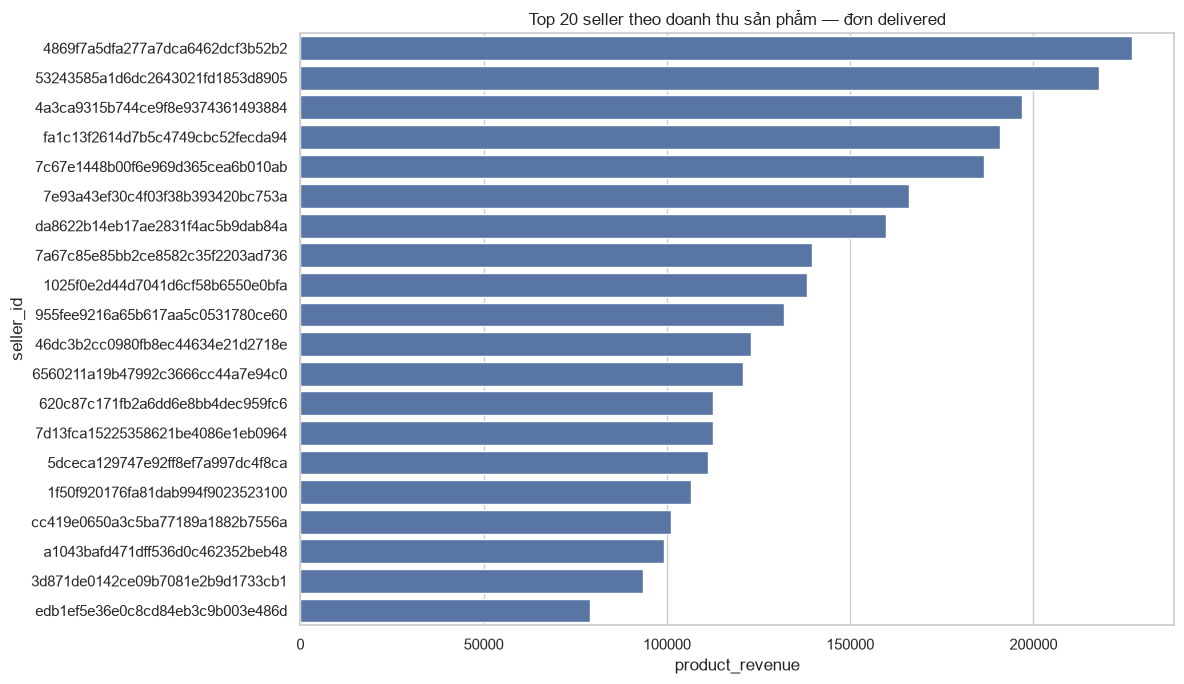

In [21]:
seller_perf = qdf("""
SELECT s.seller_id, s.state,
       COUNT(DISTINCT i.order_key) orders, COUNT(*) item_rows,
       SUM(i.price) product_revenue, SUM(i.freight_value) freight_revenue
FROM fact_order_items i
JOIN fact_orders o ON o.order_key=i.order_key
JOIN dim_seller s ON s.seller_key=i.seller_key
WHERE o.order_status='delivered'
GROUP BY s.seller_id, s.state
ORDER BY product_revenue DESC LIMIT 20
""")
display(seller_perf)
plt.figure(figsize=(12, 7))
sns.barplot(data=seller_perf, y="seller_id", x="product_revenue")
plt.title("Top 20 seller theo doanh thu sản phẩm — đơn delivered")
plt.tight_layout()
plt.show()

## 4.4. Logistics Performance — giao trễ theo bang khách hàng

,customer_state,delivered_orders_with_dates,late_orders,late_pct,mean_delivery_days,mean_delay_days
0,AL,398,85.000,21.357,24.470,-8.729
1,MA,716,125.000,17.458,21.510,-9.581
2,SE,336,51.000,15.179,21.372,-10.071
3,PI,476,66.000,13.866,19.395,-11.307
4,CE,1277,176.000,13.782,21.207,-10.799
5,RR,41,5.000,12.195,29.341,-17.293
6,BA,3256,396.000,12.162,19.278,-10.792
7,RJ,12345,"1,495.000",12.110,15.237,-11.765
8,PA,946,106.000,11.205,23.725,-14.067
9,ES,1994,214.000,10.732,15.724,-10.492


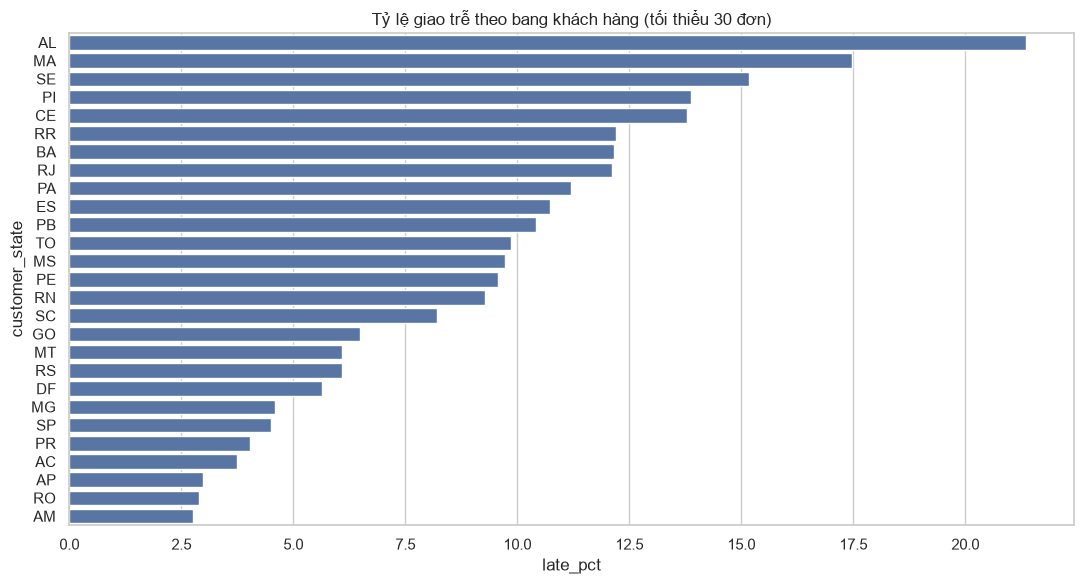

In [22]:
late_by_state = qdf("""
SELECT COALESCE(c.state, '(NULL)') customer_state,
       COUNT(*) delivered_orders_with_dates,
       SUM(CASE WHEN o.delivery_delay_days>0 THEN 1 ELSE 0 END) late_orders,
       100.0*SUM(CASE WHEN o.delivery_delay_days>0 THEN 1 ELSE 0 END)/NULLIF(COUNT(*),0) late_pct,
       AVG(o.delivery_days) mean_delivery_days,
       AVG(o.delivery_delay_days) mean_delay_days
FROM fact_orders o
JOIN dim_customer c ON c.customer_key=o.customer_key
WHERE o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
GROUP BY COALESCE(c.state, '(NULL)')
HAVING COUNT(*)>=30
ORDER BY late_pct DESC
""")
display(late_by_state)
plt.figure(figsize=(11, 6))
sns.barplot(data=late_by_state, y="customer_state", x="late_pct")
plt.title("Tỷ lệ giao trễ theo bang khách hàng (tối thiểu 30 đơn)")
plt.tight_layout()
plt.show()

## 4.5. Payment Analysis — đối chiếu ở grain đơn hàng

,count,mean,std,min,1%,50%,95%,99%,max
total_payment_value,"98,665.000",160.607,220.484,9.590,22.380,105.290,450.530,"1,063.328","13,664.080"
product_value,"98,665.000",137.754,210.646,0.850,11.976,86.900,399.900,998.900,"13,440.000"
freight_value,"98,665.000",22.824,21.651,0.000,7.390,17.170,54.960,104.984,"1,794.960"
product_plus_freight,"98,665.000",160.578,220.467,9.590,22.380,105.290,450.530,"1,063.328","13,664.080"
payment_minus_product_freight,"98,665.000",0.029,1.129,-51.620,-0.000,0.000,0.000,0.000,182.810


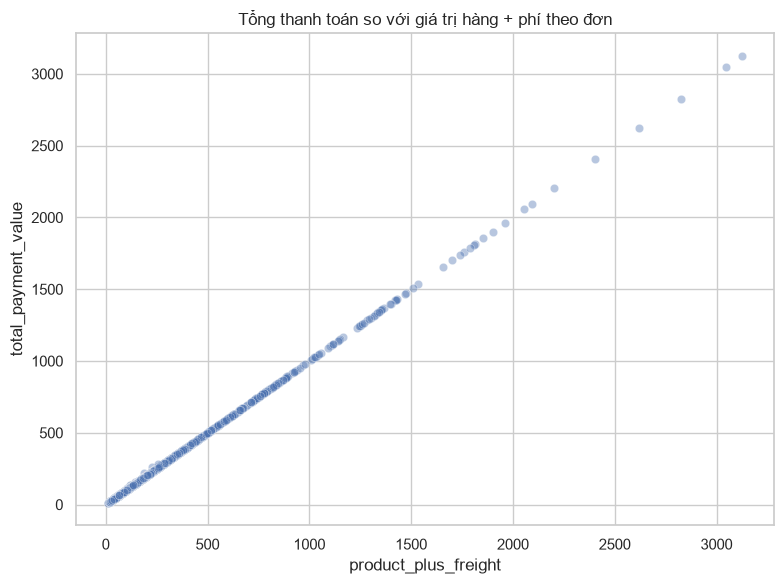

In [23]:
payments_order = qdf("""
SELECT order_key, SUM(payment_value) total_payment_value,
       COUNT(*) payment_records, COUNT(DISTINCT payment_type) distinct_payment_types,
       MAX(payment_installments) max_installments
FROM fact_payments GROUP BY order_key
""")
items_order = qdf("""
SELECT order_key, SUM(price) product_value, SUM(freight_value) freight_value,
       SUM(price+COALESCE(freight_value,0)) product_plus_freight
FROM fact_order_items GROUP BY order_key
""")
payment_compare = payments_order.merge(items_order, on="order_key", how="inner")
payment_compare["payment_minus_product_freight"] = payment_compare["total_payment_value"] - payment_compare["product_plus_freight"]
display(payment_compare[[
    "total_payment_value","product_value","freight_value",
    "product_plus_freight","payment_minus_product_freight"
]].describe(percentiles=[.01,.5,.95,.99]).T)

sample = payment_compare.sample(min(5000, len(payment_compare)), random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="product_plus_freight", y="total_payment_value", alpha=.4)
plt.title("Tổng thanh toán so với giá trị hàng + phí theo đơn")
plt.tight_layout()
plt.show()

## 4.6. Customer Satisfaction — đánh giá theo trạng thái

,order_status,orders,mean_review,median_review,low_review_rate
0,approved,2,2.500,2.500,50.000
1,canceled,577,1.752,1.000,77.990
2,created,3,2.333,1.000,66.667
3,delivered,95372,4.158,5.000,12.736
4,invoiced,308,1.617,1.000,83.117
5,processing,293,1.273,1.000,92.491
6,shipped,1022,2.007,1.000,69.276
7,unavailable,590,1.517,1.000,85.254


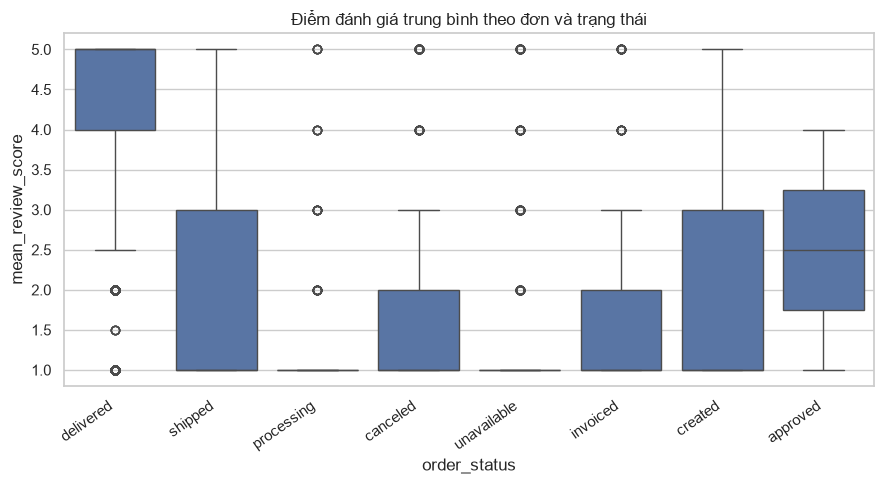

In [24]:
review_by_order = qdf("""
SELECT order_key, COUNT(*) review_records, AVG(review_score) mean_review_score,
       MIN(review_score) min_review_score, MAX(review_score) max_review_score
FROM fact_reviews
WHERE review_score BETWEEN 1 AND 5
GROUP BY order_key
""")
orders_review = qdf("""
SELECT order_key, order_status, delivery_days, delivery_delay_days,
       order_delivered_customer_date, order_estimated_delivery_date
FROM fact_orders
""")
review_analysis = orders_review.merge(review_by_order, on="order_key", how="inner")
display(review_analysis.groupby("order_status", dropna=False).agg(
    orders=("order_key","nunique"),
    mean_review=("mean_review_score","mean"),
    median_review=("mean_review_score","median"),
    low_review_rate=("mean_review_score",lambda s: (s<=2).mean()*100)
).reset_index())

plt.figure(figsize=(9, 5))
sns.boxplot(data=review_analysis, x="order_status", y="mean_review_score")
plt.xticks(rotation=35, ha="right")
plt.title("Điểm đánh giá trung bình theo đơn và trạng thái")
plt.tight_layout()
plt.show()

# Phần 05 — Statistical Analysis & Hypothesis Testing

Các kiểm định sử dụng dữ liệu quan sát. P-value nhỏ không chứng minh quan hệ nhân quả. Điểm đánh giá được tổng hợp thành một giá trị trung bình cho mỗi đơn.

## 5.1. H1 — Đơn giao trễ có điểm đánh giá thấp hơn?

In [25]:
h1 = qdf("""
SELECT o.order_key, o.delivery_days, o.delivery_delay_days,
       AVG(r.review_score) order_mean_review_score
FROM fact_orders o
JOIN fact_reviews r ON r.order_key=o.order_key
WHERE o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
  AND o.delivery_delay_days IS NOT NULL
  AND r.review_score BETWEEN 1 AND 5
GROUP BY o.order_key, o.delivery_days, o.delivery_delay_days
""")
h1["delivery_group"] = np.where(h1["delivery_delay_days"] > 0, "Late", "Early/on-time")
h1["low_review"] = (h1["order_mean_review_score"] <= 2).astype(int)
display(h1.groupby("delivery_group").agg(
    orders=("order_key","nunique"),
    mean_score=("order_mean_review_score","mean"),
    median_score=("order_mean_review_score","median"),
    low_review_rate=("low_review","mean"),
    mean_delay_days=("delivery_delay_days","mean")
).assign(low_review_rate_pct=lambda d: 100*d["low_review_rate"]))

late = h1.loc[h1.delivery_group=="Late", "order_mean_review_score"].dropna()
early = h1.loc[h1.delivery_group=="Early/on-time", "order_mean_review_score"].dropna()
if len(late) and len(early):
    test = stats.mannwhitneyu(late, early, alternative="less")
    print(f"Mann–Whitney U, kiểm tra Late < Early/on-time: U={test.statistic:,.0f}; p={test.pvalue:.6g}")
    print(f"Chênh lệch trung bình Late - Early/on-time: {late.mean()-early.mean():.4f}")
    print(f"Chênh lệch trung vị Late - Early/on-time: {late.median()-early.median():.4f}")
else:
    print("Không đủ quan sát ở cả hai nhóm.")

,orders,mean_score,median_score,low_review_rate,mean_delay_days,low_review_rate_pct
delivery_group,,,,,,
Early/on-time,89023,4.292,5.000,0.092,-13.509,9.203
Late,6347,2.272,1.000,0.623,10.519,62.344


Mann–Whitney U, kiểm tra Late < Early/on-time: U=102,068,073; p=0
Chênh lệch trung bình Late - Early/on-time: -2.0208
Chênh lệch trung vị Late - Early/on-time: -4.0000


`alternative='less'` kiểm tra nhóm Late có điểm thấp hơn nhóm Early/on-time hay không theo Mann–Whitney. Cần bổ sung khoảng tin cậy và kích thước hiệu ứng trước khi dùng làm kết luận trọng tâm.

## 5.2. H2 — Độ trễ có liên quan đến điểm đánh giá khi xét thời gian giao?

In [26]:
# OLS dùng để khám phá mối liên hệ có điều chỉnh đơn giản.
# Review score là thang thứ bậc; OLS chỉ là phân tích gần đúng, không phải mô hình nhân quả.
try:
    import statsmodels.formula.api as smf
    h2 = h1.dropna(subset=["delivery_days","delivery_delay_days","order_mean_review_score"])
    if len(h2) >= 100:
        model = smf.ols(
            "order_mean_review_score ~ delivery_days + delivery_delay_days",
            data=h2
        ).fit(cov_type="HC3")
        display(pd.DataFrame({
            "coef": model.params, "robust_se": model.bse, "p_value": model.pvalues,
            "ci_low": model.conf_int()[0], "ci_high": model.conf_int()[1]
        }))
    else:
        print(f"Không đủ complete cases: {len(h2)}")
except ImportError:
    print("Cần statsmodels: chạy %pip install statsmodels rồi chạy lại cell.")

,coef,robust_se,p_value,ci_low,ci_high
Intercept,4.460,0.012,0.000,4.437,4.483
delivery_days,-0.037,0.001,0.000,-0.038,-0.035
delivery_delay_days,-0.013,0.001,0.000,-0.014,-0.012


`delivery_days` và `delivery_delay_days` có quan hệ toán học với nhau. Kiểm tra đa cộng tuyến và diễn giải thận trọng; hệ số không phải bằng chứng về tác động độc lập chắc chắn.

## 5.3. H3 — Phân rã doanh thu theo số đơn và AOV

In [27]:
monthly_sales["reconstructed_revenue"] = monthly_sales["total_orders"] * monthly_sales["product_revenue_per_order"]
monthly_sales["revenue_reconstruction_diff"] = monthly_sales["product_revenue"] - monthly_sales["reconstructed_revenue"]
display(monthly_sales[[
    "year_month","total_orders","product_revenue","product_revenue_per_order",
    "revenue_mom_pct","orders_mom_pct","aov_mom_pct","revenue_reconstruction_diff"
]])

,year_month,total_orders,product_revenue,product_revenue_per_order,revenue_mom_pct,orders_mom_pct,aov_mom_pct,revenue_reconstruction_diff
0,2016-09,3,267.360,89.120,NaN,NaN,NaN,0.000
1,2016-10,308,"49,507.660",160.739,"18,417.228","10,166.667",80.363,0.000
2,2016-12,1,10.900,10.900,-99.978,-99.675,-93.219,0.000
3,2017-01,789,"120,312.870",152.488,"1,103,687.798","78,800.000","1,298.971",0.000
4,2017-02,1733,"247,303.020",142.702,105.550,119.645,-6.417,0.000
5,2017-03,2641,"374,344.300",141.743,51.371,52.395,-0.672,0.000
6,2017-04,2391,"359,927.230",150.534,-3.851,-9.466,6.202,0.000
7,2017-05,3660,"506,071.140",138.271,40.604,53.074,-8.147,0.000
8,2017-06,3217,"433,038.600",134.609,-14.431,-12.104,-2.648,0.000
9,2017-07,3969,"498,031.480",125.480,15.009,23.376,-6.782,0.000


Đây là phân tích phân rã mô tả; không cần p-value nếu mục tiêu chỉ là xác định thành phần đóng góp vào biến động. Đánh dấu các tháng chưa đầy đủ và kiểm tra độ nhạy theo quy tắc trạng thái đơn.

## 5.4. H4 — So sánh chi tiêu khách mua một lần và khách mua lại

In [28]:
h4 = qdf("""
SELECT customer_key, order_count, total_spent, average_order_value
FROM fact_customer_order
WHERE order_count IS NOT NULL
""")
h4["customer_group"] = np.where(h4["order_count"] > 1, "Repeat (2+)", "One order")
display(h4.groupby("customer_group").agg(
    customers=("customer_key","nunique"),
    mean_orders=("order_count","mean"),
    median_orders=("order_count","median"),
    mean_spent=("total_spent","mean"),
    median_spent=("total_spent","median"),
    mean_aov=("average_order_value","mean")
))
one = h4.loc[h4.customer_group=="One order","total_spent"].dropna()
repeat = h4.loc[h4.customer_group=="Repeat (2+)","total_spent"].dropna()
if len(one) and len(repeat):
    test = stats.mannwhitneyu(repeat, one, alternative="two-sided")
    print(f"Mann–Whitney U cho total_spent: U={test.statistic:,.0f}; p={test.pvalue:.6g}")
else:
    print("Không đủ dữ liệu để so sánh.")

,customers,mean_orders,median_orders,mean_spent,median_spent,mean_aov
customer_group,,,,,,
One order,93099,1.000,1.000,161.815,105.700,161.817
Repeat (2+),2997,2.116,2.000,314.989,225.840,148.501


Mann–Whitney U cho total_spent: U=215,397,692; p=0


Đây là so sánh giữa các nhóm được định nghĩa bởi số đơn quan sát. Không kết luận rằng mua lại gây ra chi tiêu cao hơn; nhóm khách hàng cũng có thời gian quan sát không đồng đều.

## 5.5. H5 — Khác biệt điểm đánh giá giữa các danh mục

,category,orders,mean_review,median_review,low_review_rate
58,office_furniture,1256,3.617,4.000,22.691
28,fashio_female_clothing,39,3.692,4.000,23.077
31,fashion_male_clothing,110,3.700,5.000,26.364
42,furniture_mattress_and_upholstery,35,3.829,4.000,20.000
5,audio,347,3.836,5.000,21.902
20,construction_tools_safety,166,3.849,5.000,20.482
48,home_confort,394,3.876,5.000,19.036
35,fixed_telephony,214,3.902,5.000,18.692
0,(Unknown),1434,3.912,5.000,20.014
34,fashion_underwear_beach,117,3.940,4.000,17.949


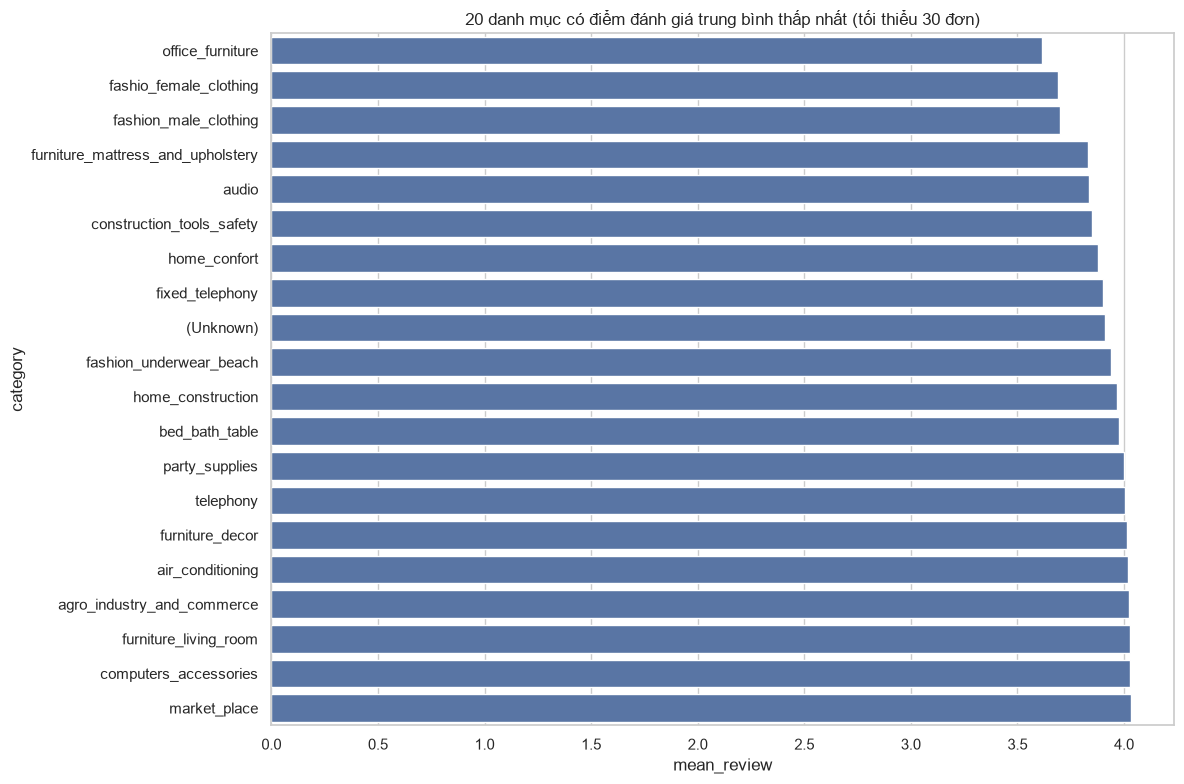

Kruskal–Wallis: H=771.9023; p=3.89843e-123; số nhóm=63


In [29]:
category_reviews = qdf("""
SELECT category, order_key, AVG(review_score) order_mean_review_score
FROM (
    SELECT COALESCE(c.product_category_name_english, p.product_category_name, '(Unknown)') category,
           r.order_key, r.review_score
    FROM fact_reviews r
    JOIN fact_order_items i ON i.order_key=r.order_key
    JOIN dim_product p ON p.product_key=i.product_key
    LEFT JOIN dim_category c ON c.category_key=p.category_key
    WHERE r.review_score BETWEEN 1 AND 5
) x
GROUP BY category, order_key
""")
cat_stats = category_reviews.groupby("category").agg(
    orders=("order_key","nunique"),
    mean_review=("order_mean_review_score","mean"),
    median_review=("order_mean_review_score","median"),
    low_review_rate=("order_mean_review_score",lambda s: 100*(s<=2).mean())
).reset_index()
cat_stats = cat_stats[cat_stats.orders >= 30].sort_values("mean_review")
display(cat_stats.head(25))

plt.figure(figsize=(12, 8))
sns.barplot(data=cat_stats.head(20), y="category", x="mean_review")
plt.title("20 danh mục có điểm đánh giá trung bình thấp nhất (tối thiểu 30 đơn)")
plt.tight_layout()
plt.show()

groups = [
    g["order_mean_review_score"].dropna().to_numpy()
    for _, g in category_reviews.groupby("category")
    if g["order_key"].nunique() >= 30
]
if len(groups) >= 2:
    kw = stats.kruskal(*groups)
    print(f"Kruskal–Wallis: H={kw.statistic:.4f}; p={kw.pvalue:.6g}; số nhóm={len(groups)}")
else:
    print("Không đủ danh mục có ít nhất 30 đơn.")

Một đơn có thể chứa nhiều danh mục, do đó có thể xuất hiện ở nhiều nhóm danh mục; trong từng danh mục, mỗi đơn chỉ được tính một lần. Nếu kiểm định tổng thể có ý nghĩa, cần post-hoc và điều chỉnh kiểm định nhiều lần trước khi khẳng định cặp danh mục khác biệt.

## 5.6. Robustness — kiểm tra độ vững và tổng hợp

In [30]:
robustness = h1.groupby("delivery_group").agg(
    orders=("order_key","nunique"),
    low_review_le_2_pct=("order_mean_review_score",lambda s: 100*(s<=2).mean()),
    low_review_le_3_pct=("order_mean_review_score",lambda s: 100*(s<=3).mean()),
    mean_score=("order_mean_review_score","mean"),
    median_score=("order_mean_review_score","median")
).reset_index()
display(robustness)

findings_template = pd.DataFrame([
    {"analysis":"H1: giao trễ và điểm đánh giá","result":"","effect_size/difference":"","p_value":"","limitations":""},
    {"analysis":"H2: độ trễ ngoài thời gian giao","result":"","effect_size/difference":"","p_value":"","limitations":""},
    {"analysis":"H3: doanh thu, số đơn và AOV","result":"","effect_size/difference":"","p_value":"Không áp dụng nếu chỉ phân rã mô tả","limitations":""},
    {"analysis":"H4: nhóm khách mua lại và chi tiêu","result":"","effect_size/difference":"","p_value":"","limitations":""},
    {"analysis":"H5: khác biệt đánh giá theo danh mục","result":"","effect_size/difference":"","p_value":"","limitations":""},
])
display(findings_template)

,delivery_group,orders,low_review_le_2_pct,low_review_le_3_pct,mean_score,median_score
0,Early/on-time,89023,9.203,17.274,4.292,5.000
1,Late,6347,62.344,73.279,2.272,1.000


,analysis,result,effect_size/difference,p_value,limitations
0,H1: giao trễ và điểm đánh giá,,,,
1,H2: độ trễ ngoài thời gian giao,,,,
2,"H3: doanh thu, số đơn và AOV",,,Không áp dụng nếu chỉ phân rã mô tả,
3,H4: nhóm khách mua lại và chi tiêu,,,,
4,H5: khác biệt đánh giá theo danh mục,,,,


# Checklist trước khi viết kết luận

- [ ] Đúng database `olist_dw`, đúng port/user/password.
- [ ] Đã kiểm tra đủ 11 bảng.
- [ ] Đã xem các vấn đề NULL, uniqueness, miền giá trị và khóa ngoại.
- [ ] Đã xác nhận công thức ETL của `item_total`, `delivery_days`, `delivery_delay_days`, `total_spent`, `average_order_value`.
- [ ] Đã chốt trạng thái đơn được tính vào doanh thu.
- [ ] Đã đánh dấu tháng không đầy đủ.
- [ ] Đã tổng hợp fact về đúng grain trước khi JOIN.
- [ ] Kết quả kiểm định có cỡ mẫu, kích thước hiệu ứng, p-value và giới hạn; không chỉ p-value.

Notebook chỉ đối soát nội bộ DW. Để kiểm tra trực tiếp CURATED–DW, cần cung cấp kết nối/đường dẫn MinIO hoặc báo cáo đối soát từ pipeline.